In [1]:
import pandas as pd
import numpy as np
from plotnine import *
import xgboost as xgb
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.model_selection import ParameterGrid
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
import shap
from sklearn.model_selection import StratifiedGroupKFold

## Setup
I kept 1976–2019 since more recent cases might still get solved.

In [2]:
df = pd.read_csv("../data/clean.csv")
df = df[df["Year"] <= 2019]
df.shape

(793144, 13)

793,144 murders.

I split the data 80/20, stratified on solved. Victims from the same incident share an outcome, so I kept each incident (ID) on one side of the split. Otherwise the model could learn one victim's outcome from another victim of the same incident.

In [3]:
split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=123)
train_idx, test_idx = next(split.split(df, df["solved"], groups=df["ID"]))

train = df.iloc[train_idx]
test = df.iloc[test_idx]

In [4]:
class_counts = train['solved'].value_counts(normalize=True)
print(class_counts)
class_counts2 = test['solved'].value_counts(normalize=True)
print(class_counts2)

solved
1    0.701167
0    0.298833
Name: proportion, dtype: float64
solved
1    0.701166
0    0.298834
Name: proportion, dtype: float64


Both halves are 70.1% solved, so always guessing "solved" would be right 70.1% of the time. That's the number to beat.

I left out ID and county. County has too many levels to use as a feature.

In [5]:
X_train = train.drop(columns=["ID", "CNTYFIPS", "solved"])
X_test = test.drop(columns=["ID", "CNTYFIPS", "solved"])

y_train = pd.Categorical(train['solved'])
y_test  = pd.Categorical(test['solved'])

In [6]:
cat_cols = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

cats_map_tr = {c: sorted(X_train[c].dropna().unique().tolist()) for c in cat_cols}
ohe_categories_tr = [cats_map_tr[c] for c in cat_cols]

preprocess_tr = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(categories=ohe_categories_tr, handle_unknown="ignore", sparse_output=False, drop=None), cat_cols),
        ("num", SimpleImputer(strategy="median"), num_cols),
    ],
    remainder="drop",
).fit(X_train)

X_train_trans = preprocess_tr.transform(X_train)
X_test_trans = preprocess_tr.transform(X_test)
feature_names = preprocess_tr.get_feature_names_out()

In [7]:
print(cat_cols)
print(num_cols)
print(X_train_trans.shape, X_test_trans.shape)

['State', 'Agentype', 'Month', 'VicSex', 'VicRace', 'VicEthnic', 'Weapon']
['Year', 'VicAge', 'VicCount']
(634514, 102) (158630, 102)


102 features after one-hot encoding.

In [8]:
dtrain = xgb.DMatrix(data=pd.DataFrame(X_train_trans, columns=feature_names), label=y_train)
dtest  = xgb.DMatrix(data=pd.DataFrame(X_test_trans, columns=feature_names),  label=y_test)

In [9]:
cv_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=111111)
                .split(train, train["solved"], groups=train["ID"]))

## Baseline and Tuning
I started with a default XGBoost model to see where it lands before tuning.

In [10]:
params = {
        "objective": "binary:logistic",
        "eval_metric": ["auc", "error"],
        "tree_method": "hist",
        "seed": 42,

    }
num_boost_round = 300

In [11]:
watchlist = [(dtrain, "train")]
booster = xgb.train(params,
                    dtrain,
                    num_boost_round=num_boost_round,
                    evals=watchlist,
                    verbose_eval=50)

[0]	train-auc:0.66149	train-error:0.29883
[50]	train-auc:0.74598	train-error:0.26337
[100]	train-auc:0.75577	train-error:0.25928
[150]	train-auc:0.76153	train-error:0.25688
[200]	train-auc:0.76700	train-error:0.25443
[250]	train-auc:0.77072	train-error:0.25271
[299]	train-auc:0.77491	train-error:0.25066


In [12]:
test_pred_raw = booster.predict(dtest)
test_pred_raw

array([0.6612674 , 0.92359114, 0.9368848 , ..., 0.98733705, 0.95752037,
       0.9802669 ], shape=(158630,), dtype=float32)

In [13]:
test_pred_cls = (test_pred_raw >= 0.5).astype(int)

base_rate = test['solved'].value_counts(normalize=True).max()
print(f"No-information rate (always predict the majority class): {base_rate:.4f}")

No-information rate (always predict the majority class): 0.7012



Confusion matrix:


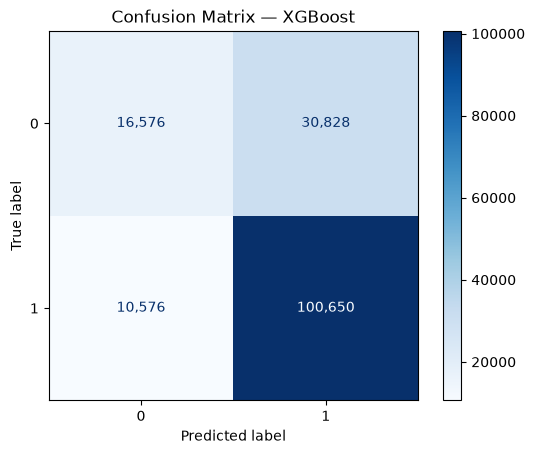


Accuracy):
0.7389901027548383

AUC:
0.7463775637894898


In [14]:
print("\nConfusion matrix:")
cm = (confusion_matrix(y_test, test_pred_cls))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", values_format=",d")
plt.title("Confusion Matrix — XGBoost")
plt.show()
print("\nAccuracy):")
print(accuracy_score(y_test, test_pred_cls))
print("\nAUC:")
print(roc_auc_score(y_test, test_pred_raw))

Accuracy is 0.739 against 0.701 for guessing, and AUC is 0.746, so it ranks a solved murder above an unsolved one about 75% of the time. I'm watching AUC more, since accuracy is already high from guessing "solved."

I used 5-fold cross-validation to see how many rounds it needs.

In [15]:
params = {
    "objective": "binary:logistic",
    "eta": 0.1,
    "eval_metric": ["auc", "error"],
    "tree_method": "hist",
    "seed": 111111,
}

cv_res = xgb.cv(
    params=params,
    dtrain=dtrain,
    num_boost_round=400,
    folds=cv_folds,
    verbose_eval=20,
)
cv_res.head()

[0]	train-auc:0.66159+0.00028	train-error:0.29883+0.00000	test-auc:0.66057+0.00157	test-error:0.29883+0.00000
[20]	train-auc:0.71559+0.00083	train-error:0.28589+0.00049	test-auc:0.71306+0.00092	test-error:0.28673+0.00069
[40]	train-auc:0.72713+0.00047	train-error:0.27409+0.00077	test-auc:0.72336+0.00072	test-error:0.27543+0.00060
[60]	train-auc:0.73343+0.00042	train-error:0.26971+0.00045	test-auc:0.72823+0.00071	test-error:0.27152+0.00105
[80]	train-auc:0.73784+0.00056	train-error:0.26731+0.00039	test-auc:0.73150+0.00085	test-error:0.26951+0.00076
[100]	train-auc:0.74073+0.00066	train-error:0.26608+0.00040	test-auc:0.73347+0.00100	test-error:0.26862+0.00096
[120]	train-auc:0.74318+0.00058	train-error:0.26508+0.00031	test-auc:0.73501+0.00091	test-error:0.26787+0.00058
[140]	train-auc:0.74538+0.00050	train-error:0.26418+0.00032	test-auc:0.73633+0.00083	test-error:0.26721+0.00069
[160]	train-auc:0.74723+0.00061	train-error:0.26326+0.00034	test-auc:0.73735+0.00098	test-error:0.26681+0.0007

,train-auc-mean,train-auc-std,train-error-mean,train-error-std,test-auc-mean,test-auc-std,test-error-mean,test-error-std
0,0.661592,0.000276,0.298833,6.662654e-07,0.660569,0.001565,0.298833,0.000003
1,0.681081,0.000447,0.298833,6.662654e-07,0.680002,0.001123,0.298833,0.000003
2,0.686221,0.000787,0.298833,6.662654e-07,0.684773,0.001344,0.298833,0.000003
3,0.686936,0.001440,0.298833,6.662654e-07,0.685818,0.001060,0.298833,0.000003
4,0.689353,0.001060,0.298822,2.230269e-05,0.688147,0.000510,0.298830,0.000009


In [16]:
best_idx = cv_res['test-error-mean'].idxmin()
best_iter = int(best_idx) + 1
best_err  = float(cv_res.loc[best_idx, 'test-error-mean'])
best_auc  = float(cv_res.loc[best_idx, 'test-auc-mean']) if 'test-auc-mean' in cv_res.columns else np.nan

print(f"Best iteration (by min test error): {best_iter}")
print(f"Min test error at best iter: {best_err:.6f}")
if not np.isnan(best_auc):
    print(f"Test AUC at best iter: {best_auc:.6f}")

Best iteration (by min test error): 399
Min test error at best iter: 0.263876
Test AUC at best iter: 0.743531


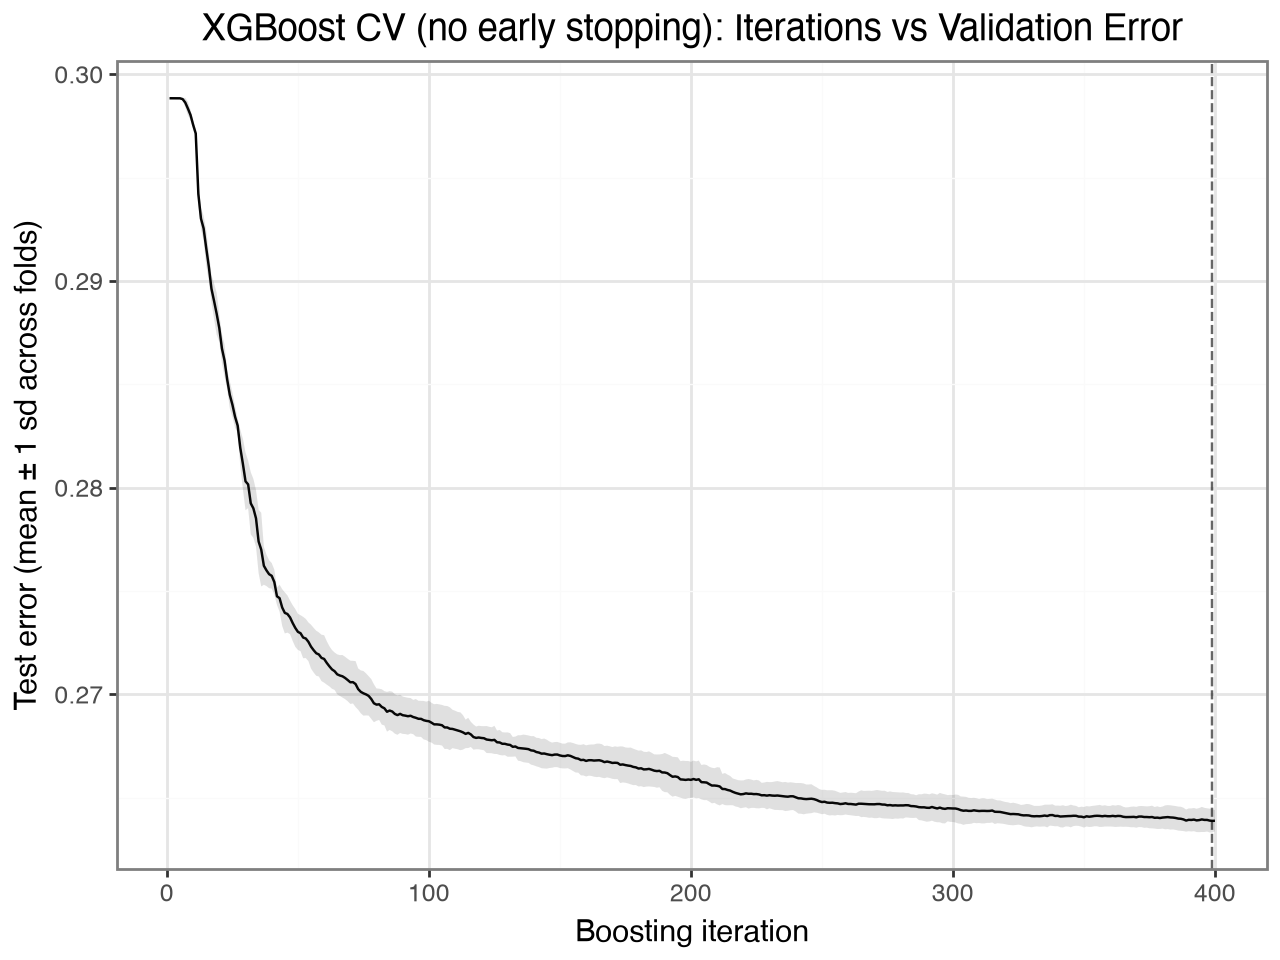

In [17]:
df_plot = cv_res.reset_index().rename(columns={"index": "iter"})
df_plot["iter"] = df_plot["iter"] + 1

df_plot = df_plot.rename(columns=lambda c: c.replace("-", "_"))
df_plot["test_error_lower"] = df_plot["test_error_mean"] - df_plot["test_error_std"]
df_plot["test_error_upper"] = df_plot["test_error_mean"] + df_plot["test_error_std"]

p_err = (
    ggplot(df_plot,
           aes(x="iter", y="test_error_mean"))
    + geom_line()
    + geom_ribbon(aes(ymin="test_error_lower", ymax="test_error_upper"), alpha=0.15)
    + geom_vline(xintercept=best_iter, linetype="dashed", alpha=0.6)
    + theme_bw()
    + labs(
        title="XGBoost CV (no early stopping): Iterations vs Validation Error",
        x="Boosting iteration",
        y="Test error (mean ± 1 sd across folds)"
    )
)
p_err

Error is still dropping at 400 rounds, so I let early stopping pick the rounds in the grid search.

Then I tried a grid of tree depths and min child weights.

In [18]:
grid = {
    "max_depth": [3,  7, 10],
    "min_child_weight": [ 5, 7, 10],
}
param_grid = list(ParameterGrid(grid))

base_params = {
    "objective": "binary:logistic",
    "eta": 0.10,
    "eval_metric": ["error", "auc"],
    "tree_method": "hist",
    "seed": 111111,
}

In [19]:
def run_one_cv(md, mcw):
    params = base_params.copy()
    params.update({"max_depth": int(md), "min_child_weight": int(mcw)})

    cv = xgb.cv(
        params=params,
        dtrain=dtrain,
        num_boost_round=1000,
        folds=cv_folds,
        early_stopping_rounds=20,
        verbose_eval=False,
        seed=111111,
    )

    best_round = len(cv)

    best_row = cv.iloc[best_round - 1]
    best_err = float(best_row["test-error-mean"])
    best_auc = float(best_row["test-auc-mean"])

    return {
        "max_depth": md,
        "min_child_weight": mcw,
        "best_round": best_round,
        "test_error": best_err,
        "test_auc": best_auc,
    }

In [20]:
results = []
for p in tqdm(param_grid, desc="Grid CV (serial)"):
    results.append(run_one_cv(p["max_depth"], p["min_child_weight"]))

Grid CV (serial): 100%|██████████| 9/9 [28:10<00:00, 187.83s/it]


In [21]:
cv_results_df = (
    pd.DataFrame(results)
      .sort_values(["test_auc", "test_error"], ascending=[False, True])
      .reset_index(drop=True)
)
display(cv_results_df)

best_pair = cv_results_df.iloc[0].to_dict()
print("Best (by max test_auc, then min test_error):", best_pair)

,max_depth,min_child_weight,best_round,test_error,test_auc
0,7,5,496,0.263019,0.745643
1,7,10,589,0.262924,0.745636
2,7,7,528,0.263143,0.745583
3,10,7,291,0.262916,0.745509
4,10,10,273,0.263000,0.745451
5,10,5,262,0.263080,0.745143
6,3,10,1000,0.266270,0.738834
7,3,5,1000,0.266038,0.738717
8,3,7,1000,0.266120,0.738695


Best (by max test_auc, then min test_error): {'max_depth': 7.0, 'min_child_weight': 5.0, 'best_round': 496.0, 'test_error': 0.2630186258117723, 'test_auc': 0.7456434092274916}


Depth 7 with min child weight 5 did best (AUC 0.7456, 496 rounds). Depth 3 was clearly worse (0.739), so the trees need some depth to pick up interactions. The top six settings were all within 0.0005 of each other, so depth and child weight barely matter past depth 3.

Next I tuned gamma, which makes a split only happen if it improves the model by at least that much.

In [22]:
gamma_vals = [0.0, 0.5, 1.0, 5.0, 10.0]

base_params = {
    "objective": "binary:logistic",
    "eta": 0.10,
    "max_depth": int(best_pair["max_depth"]),
    "min_child_weight": int(best_pair["min_child_weight"]),
    "tree_method": "hist",
    "eval_metric": ["error", "auc"],
    "seed": 111111,
}

rows = []
for g in tqdm(gamma_vals, desc="Gamma CV"):
    params_2 = dict(base_params, gamma=float(g))
    cv = xgb.cv(params=params_2, dtrain=dtrain, num_boost_round=1000, folds=cv_folds, early_stopping_rounds=20,
                verbose_eval=False, seed=111111)
    best_row = cv.iloc[len(cv) - 1]
    rows.append({"gamma": g, "best_round": len(cv),
                 "test_auc": float(best_row["test-auc-mean"]), "test_error": float(best_row["test-error-mean"])})

Gamma CV: 100%|██████████| 5/5 [07:02<00:00, 84.60s/it] 


In [23]:
gamma_results = (
    pd.DataFrame(rows)
      .sort_values(["test_auc", "test_error"], ascending=[False, True])
      .reset_index(drop=True)
)
display(gamma_results)

tuned_gamma = float(gamma_results.loc[0, "gamma"])
print("Best gamma:", tuned_gamma)

,gamma,best_round,test_auc,test_error
0,0.0,496,0.745643,0.263019
1,0.5,312,0.744034,0.263506
2,1.0,265,0.743118,0.263780
3,5.0,171,0.740040,0.265017
4,10.0,127,0.737348,0.266360


Best gamma: 0.0


Gamma 0 won (AUC 0.7456). Every higher gamma did a little worse, so the trees didn't need the extra limit on splits.

Then I tuned subsample (the share of rows each tree sees) and colsample_bytree (the share of columns).

In [24]:
subsamples = [0.6, 0.8, 1.0]
colsamples = [0.6, 0.8, 1.0]

base_params = dict(base_params, gamma=tuned_gamma)

rows = []
for cs in tqdm(colsamples, desc="Colsample"):
    for ss in subsamples:
        params_3 = dict(base_params, subsample=float(ss), colsample_bytree=float(cs))
        cv = xgb.cv(params=params_3, dtrain=dtrain, num_boost_round=1000, folds=cv_folds, early_stopping_rounds=20,
                    verbose_eval=False, seed=111111)
        best_row = cv.iloc[len(cv) - 1]
        rows.append({"subsample": ss, "colsample_bytree": cs, "best_round": len(cv),
                     "test_auc": float(best_row["test-auc-mean"]), "test_error": float(best_row["test-error-mean"])})

Colsample: 100%|██████████| 3/3 [23:52<00:00, 477.48s/it]


In [25]:
sc_results = (
    pd.DataFrame(rows)
      .sort_values(["test_auc", "test_error"], ascending=[False, True])
      .reset_index(drop=True)
)
display(sc_results)

tuned_subsample = float(sc_results.loc[0, "subsample"])
tuned_colsample = float(sc_results.loc[0, "colsample_bytree"])
print("Best subsample:", tuned_subsample, "| Best colsample:", tuned_colsample)

,subsample,colsample_bytree,best_round,test_auc,test_error
0,1.0,0.8,637,0.746063,0.263011
1,1.0,0.6,580,0.746060,0.263022
2,0.8,0.8,505,0.746034,0.262915
3,0.8,1.0,526,0.745898,0.262787
4,0.8,0.6,507,0.745896,0.263041
5,1.0,1.0,496,0.745643,0.263019
6,0.6,1.0,445,0.745409,0.263116
7,0.6,0.8,384,0.745381,0.263105
8,0.6,0.6,436,0.745366,0.263165


Best subsample: 1.0 | Best colsample: 0.8


Subsample 1.0 with colsample 0.8 won (AUC 0.7461), only 0.0004 better than using every row and column, so sampling barely mattered.

Last, I tried different learning rates (eta). A smaller eta takes smaller steps, so it needs more trees.

In [26]:
etas = [0.3, 0.1, 0.05, 0.01, 0.005]

base_params = dict(base_params, subsample=tuned_subsample, colsample_bytree=tuned_colsample)
base_params.pop("eta")

curves = []
for eta in tqdm(etas, desc="Eta CV"):
    params_4 = dict(base_params, eta=float(eta))
    cv = xgb.cv(params=params_4, dtrain=dtrain, num_boost_round=1000, folds=cv_folds, early_stopping_rounds=100,
                verbose_eval=False, seed=111111)
    df_log = cv.reset_index().rename(columns={"index": "iter"})
    df_log["iter"] = df_log["iter"] + 1
    df_log = df_log.rename(columns={c: c.replace("-", "_") for c in df_log.columns})
    df_log["eta"] = str(eta)
    curves.append(df_log)

curves_df = pd.concat(curves, ignore_index=True)

Eta CV: 100%|██████████| 5/5 [18:55<00:00, 227.06s/it]


In [27]:
summ_df = (
    curves_df
    .groupby("eta", as_index=False, sort=False)
    .agg(
        best_round=("iter", "max"),
        test_error=("test_error_mean", "last"),
        test_auc=("test_auc_mean", "last"),
    )
)
summ_df["eta"] = summ_df["eta"].astype(float)
summ_df = summ_df.sort_values(["test_auc", "test_error"], ascending=[False, True]).reset_index(drop=True)
display(summ_df)

tuned_eta = float(summ_df.loc[0, "eta"])
best_round = int(summ_df.loc[0, "best_round"])
print("Best eta:", tuned_eta, "| Rounds:", best_round)

,eta,best_round,test_error,test_auc
0,0.100,637,0.263011,0.746063
1,0.050,1000,0.262803,0.746033
2,0.300,190,0.263066,0.744302
3,0.010,1000,0.267167,0.735770
4,0.005,1000,0.271011,0.729795


Best eta: 0.1 | Rounds: 637


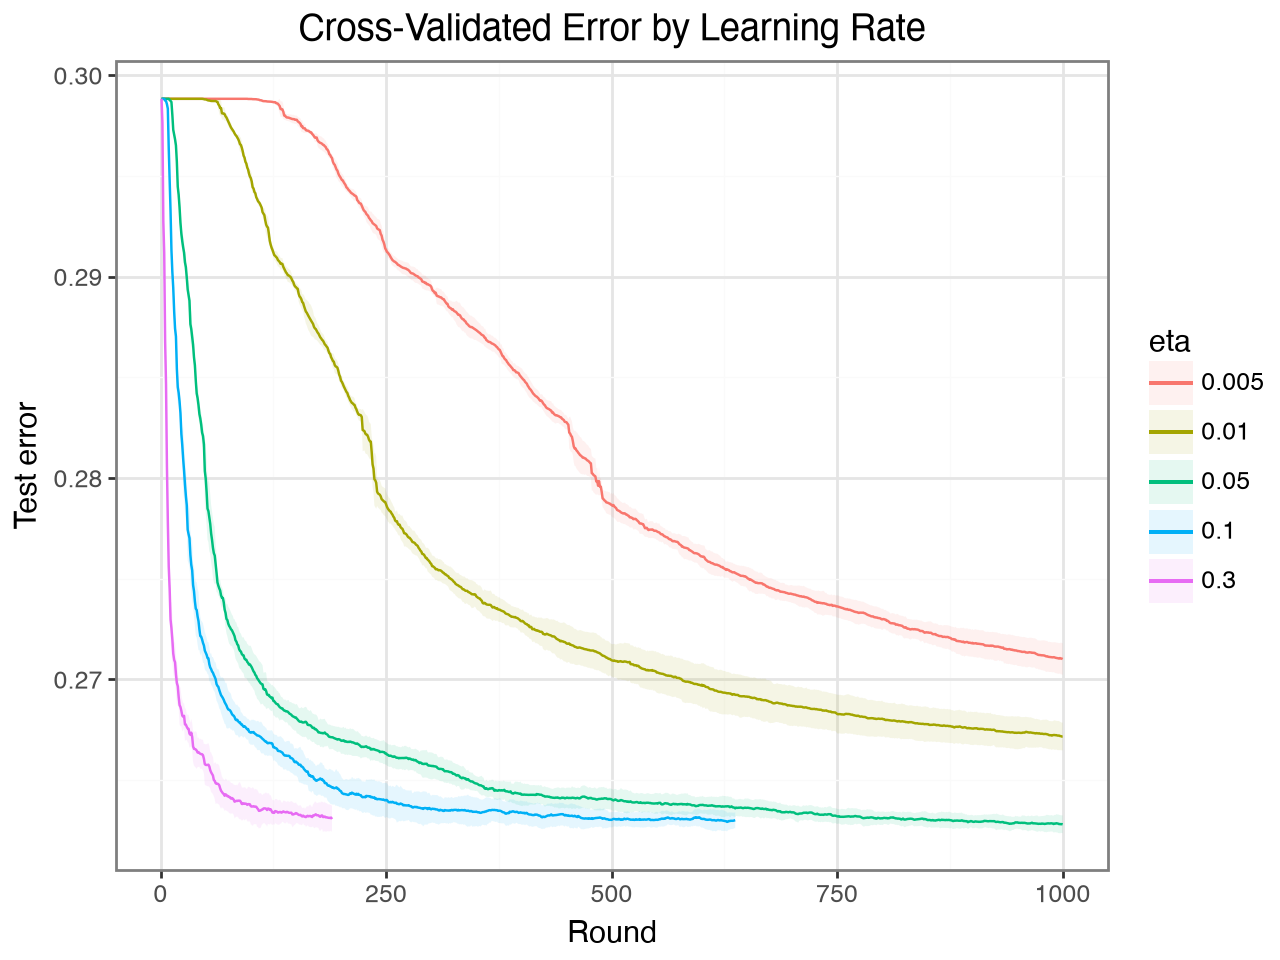

In [28]:
plot_curves = curves_df.assign(
    y_lower=curves_df["test_error_mean"] - curves_df["test_error_std"],
    y_upper=curves_df["test_error_mean"] + curves_df["test_error_std"],
)

(ggplot(plot_curves, aes(x="iter", y="test_error_mean", color="eta", fill="eta"))
 + geom_line()
 + geom_ribbon(aes(ymin="y_lower", ymax="y_upper"), alpha=0.1, color=None)
 + theme_bw()
 + labs(title="Cross-Validated Error by Learning Rate", x="Round", y="Test error", color="eta", fill="eta"))

Eta 0.1 won (AUC 0.7461, 637 rounds). Eta 0.05 was almost the same but used all 1,000 rounds. Eta 0.01 and 0.005 were still improving at 1,000 rounds, so they'd need a lot more trees to catch up.

## Final Model
I fit the final model with the tuned settings.

In [29]:
tuned_max_depth = int(best_pair["max_depth"])
tuned_min_child = int(best_pair["min_child_weight"])

In [30]:
params = {
    "objective": "binary:logistic",
    "eval_metric": ["auc", "error"],
    "max_depth": tuned_max_depth,
    "min_child_weight": tuned_min_child,
    "gamma": tuned_gamma,
    "subsample": tuned_subsample,
    "colsample_bytree": tuned_colsample,
    "eta": tuned_eta,
    "tree_method": "hist",
    "seed": 111111,
}

n_final = best_round
watchlist = [(dtrain, "train")]
xgb_tuned = xgb.train(params,
                    dtrain,
                    num_boost_round=n_final,
                    evals=watchlist,
                    verbose_eval=50)

[0]	train-auc:0.65112	train-error:0.29883
[50]	train-auc:0.73414	train-error:0.26994
[100]	train-auc:0.74461	train-error:0.26420
[150]	train-auc:0.74963	train-error:0.26192
[200]	train-auc:0.75363	train-error:0.26002
[250]	train-auc:0.75663	train-error:0.25892
[300]	train-auc:0.76030	train-error:0.25751
[350]	train-auc:0.76308	train-error:0.25632
[400]	train-auc:0.76574	train-error:0.25536
[450]	train-auc:0.76818	train-error:0.25433
[500]	train-auc:0.77017	train-error:0.25333
[550]	train-auc:0.77195	train-error:0.25248
[600]	train-auc:0.77353	train-error:0.25169
[636]	train-auc:0.77487	train-error:0.25103



Confusion matrix:


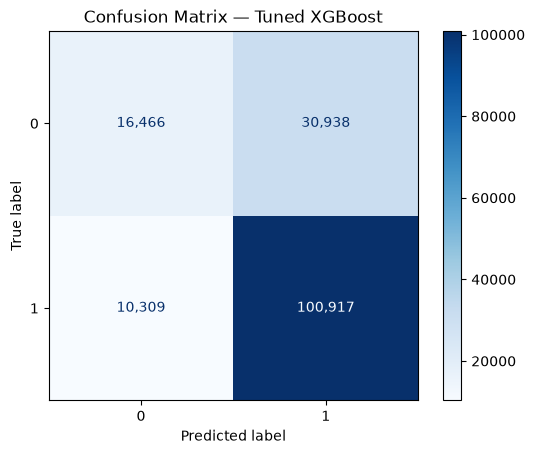


Accuracy):
0.739979827271008

AUC:
0.7481377488315677


In [31]:
test_pred_tuned = xgb_tuned.predict(dtest)

test_pred_cls_t = (test_pred_tuned >= 0.5).astype(int)

print("\nConfusion matrix:")
cm = (confusion_matrix(y_test, test_pred_cls_t))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", values_format=",d")
plt.title("Confusion Matrix — Tuned XGBoost")
plt.show()
print("\nAccuracy):")
print(accuracy_score(y_test, test_pred_cls_t))
print("\nAUC:")
print(roc_auc_score(y_test, test_pred_tuned))

Accuracy 0.740 and AUC 0.748, only a little better than the default, which matches the small gains in the grid. Most of its mistakes are unsolved murders it predicted as solved (30,938), since it leans toward the 70% that get solved.

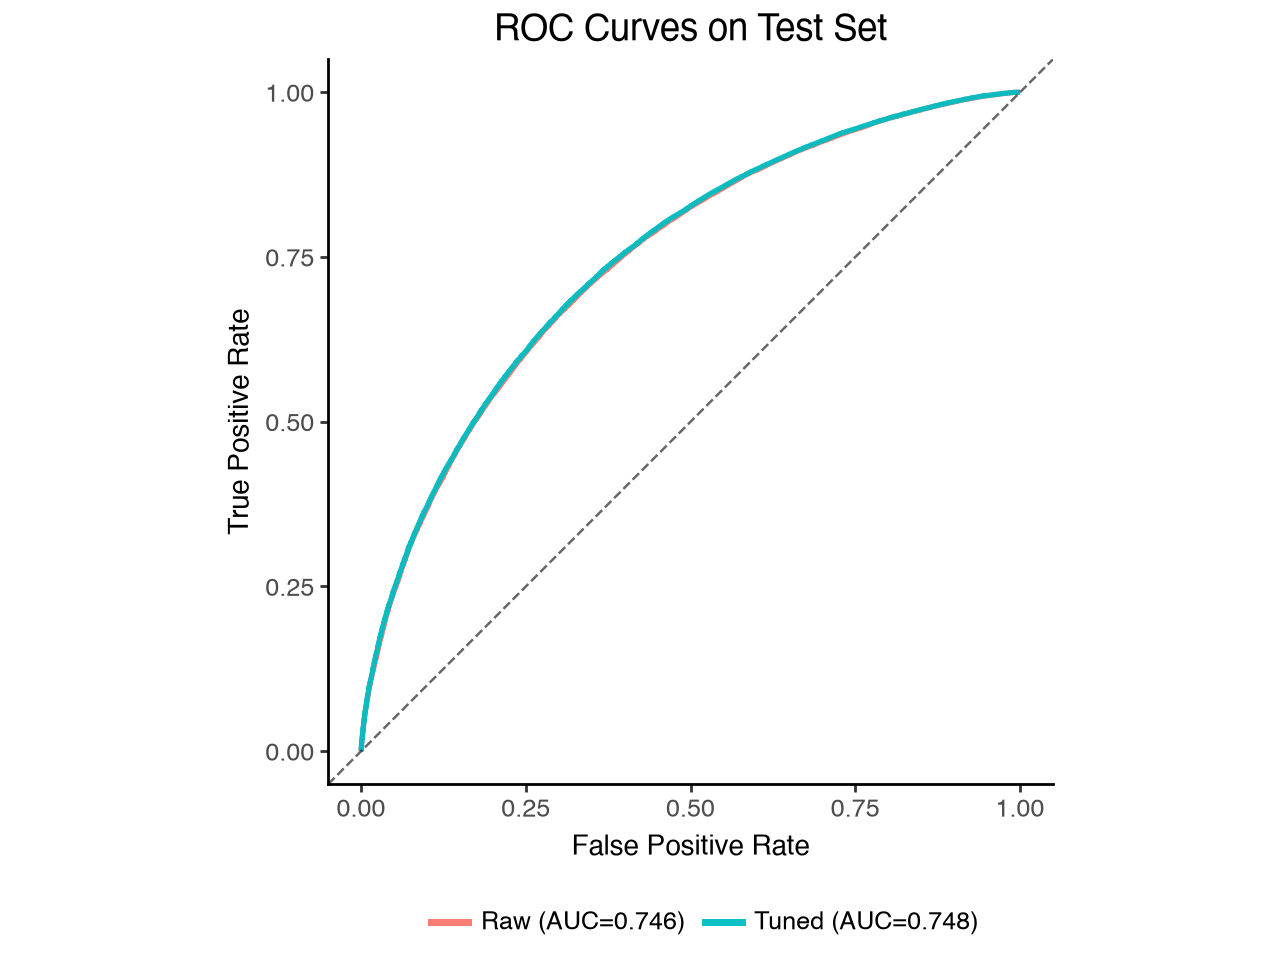

In [32]:
pred_dict = {}
pred_dict['Raw']      = np.asarray(test_pred_raw).ravel()
pred_dict['Tuned']    = np.asarray(test_pred_tuned).ravel()

curves = []
aucs = {}
for name, preds in pred_dict.items():
    fpr, tpr, _ = roc_curve(y_test, preds)
    auc_val = roc_auc_score(y_test, preds)
    aucs[name] = auc_val
    curves.append(pd.DataFrame({"fpr": fpr, "tpr": tpr, "Model": name}))

df_curves = pd.concat(curves, ignore_index=True)
df_curves["Label"] = df_curves["Model"].map(lambda m: f"{m} (AUC={aucs[m]:.3f})")

p_roc = (
    ggplot(df_curves,
           aes(x="fpr", y="tpr", color="Label"))
    + geom_line(size=1.05, alpha=0.95)
    + geom_abline(intercept=0, slope=1, linetype="dashed", alpha=0.6)
    + coord_equal()
    + theme_classic()
    + theme(
        legend_position="bottom",
        legend_title=element_text(size=9),
        legend_text=element_text(size=9),
        axis_text=element_text(size=9),
        axis_title=element_text(size=10)
    )
    + labs(
        title="ROC Curves on Test Set",
        x="False Positive Rate",
        y="True Positive Rate",
        color=""
    )
)
p_roc

The two curves are almost on top of each other, so tuning only helped a little.

In [33]:
imp_gain       = xgb_tuned.get_score(importance_type='gain')
imp_weight     = xgb_tuned.get_score(importance_type='weight')
imp_cover      = xgb_tuned.get_score(importance_type='cover')
imp_total_gain = xgb_tuned.get_score(importance_type='total_gain')
imp_total_cov  = xgb_tuned.get_score(importance_type='total_cover')

def to_df(d, kind):
    if not d:
        return pd.DataFrame(columns=['feature','kind','value'])
    df = (pd.Series(d).rename_axis('feature')
                      .reset_index(name='value'))
    df['kind'] = kind
    return df

imp_long = pd.concat([
    to_df(imp_gain, 'gain'),
    to_df(imp_weight, 'weight'),
    to_df(imp_cover, 'cover'),
    to_df(imp_total_gain, 'total_gain'),
    to_df(imp_total_cov, 'total_cover'),
], ignore_index=True)

In [34]:
imp_wide = (imp_long
            .pivot_table(index='feature', columns='kind', values='value', aggfunc='first')
            .reset_index())

top15_feats = (imp_wide.sort_values('total_gain', ascending=False)
                        .head(15)['feature'].tolist())
top15_feats

['num__Year',
 'num__VicAge',
 'cat__Weapon_Firearm, type not stated',
 'cat__State_New York',
 'cat__Weapon_Handgun - pistol, revolver, etc',
 'cat__Weapon_Other or type unknown',
 'cat__State_California',
 'cat__Weapon_Knife or cutting instrument',
 'cat__VicSex_Female',
 'cat__Agentype_Municipal police',
 'cat__VicRace_Black',
 'cat__State_District of Columbia',
 'cat__State_Illinois',
 'cat__VicRace_White',
 'num__VicCount']

Year and victim age matter most, then weapon, state, and victim sex. "Other or type unknown" weapon might leak a little, since how much police know about the weapon can depend on whether they solved it.

## SHAP Values
Importance shows which features the model uses, but not which way they push. SHAP values show how much each feature raised or lowered each murder's predicted chance of being solved. I used a random sample of 5,000 training murders to keep it fast.

In [35]:
X_shap = pd.DataFrame(X_train_trans, columns=feature_names).sample(5000, random_state=123)

explainer = shap.TreeExplainer(xgb_tuned)
shap_values = explainer(X_shap)
print(shap_values.values.shape)

(5000, 102)


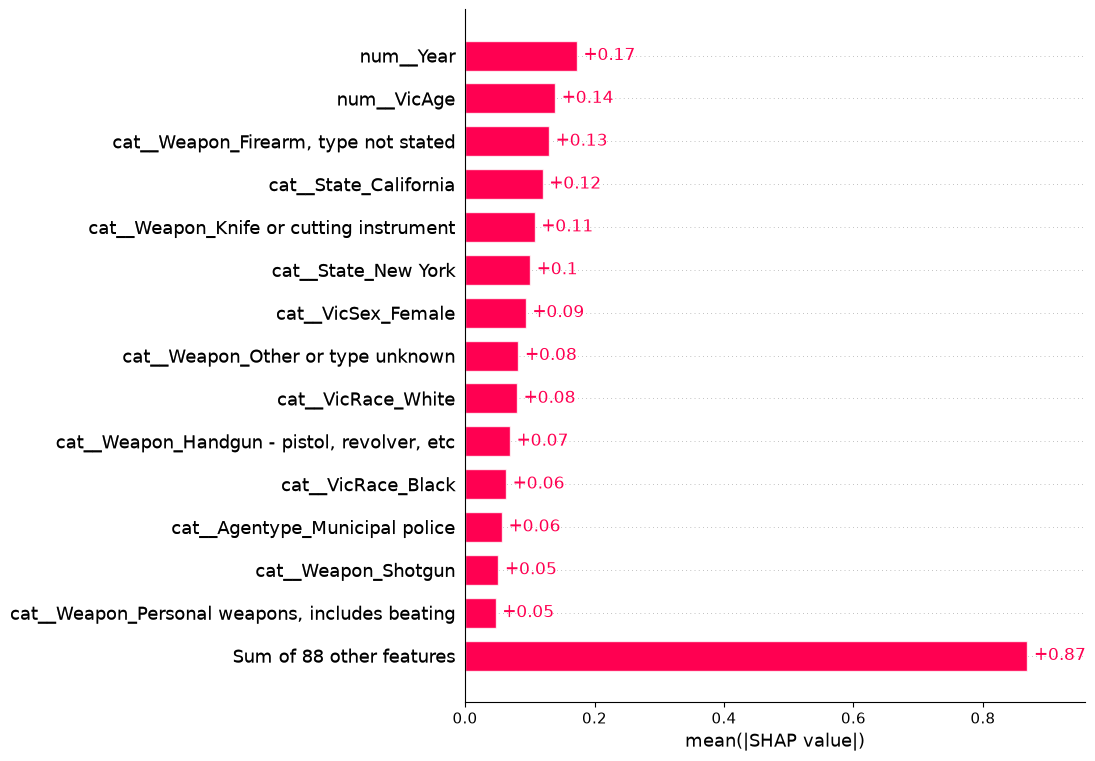

In [36]:
shap.plots.bar(shap_values, max_display=15)

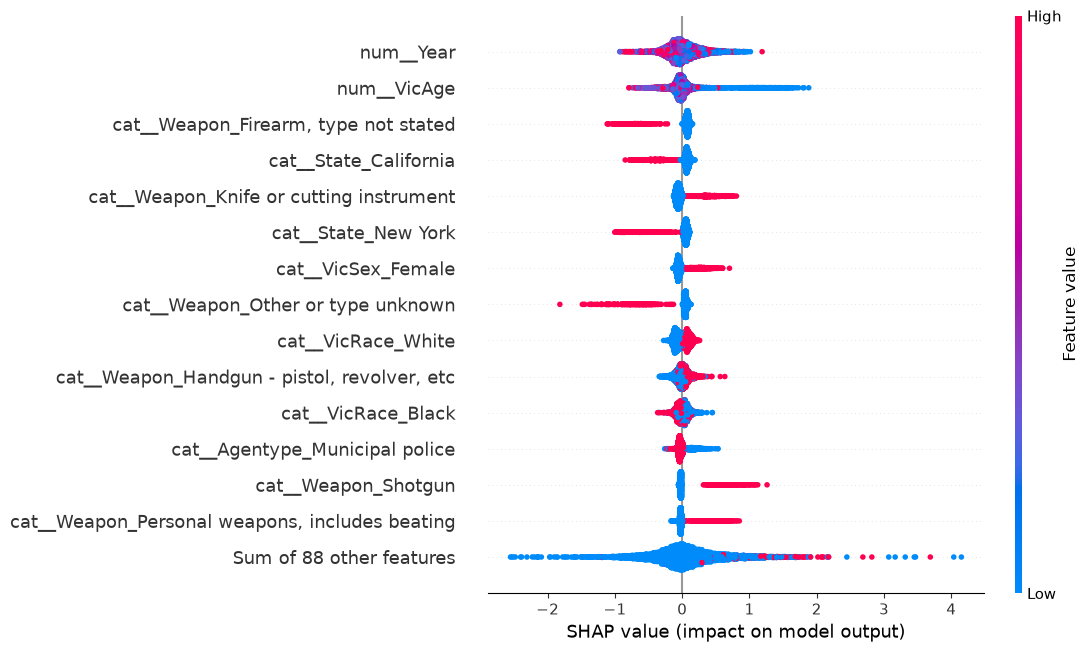

In [37]:
shap.plots.beeswarm(shap_values, max_display=15)

## Out-of-Fold Scoring

Parts 3–5 compare each group's actual solves with what the model expected. If the model was trained on a murder, it partly remembers whether it was solved, so unsolved clusters look less unusual than they are. To avoid that, I split all murders into 5 folds (keeping incidents together), trained on 4 folds with my tuned settings, and predicted the 5th. Every murder gets a prediction from a model that never saw it.

In [38]:
X_all = df.drop(columns=["ID", "CNTYFIPS", "solved"])

X_fixed = X_all.copy()
X_fixed["Year"] = 1990

X_white = X_all.copy()
X_white["VicRace"] = "White"

X_all_trans   = pd.DataFrame(preprocess_tr.transform(X_all),   columns=feature_names).astype(np.float32)
X_fixed_trans = pd.DataFrame(preprocess_tr.transform(X_fixed), columns=feature_names).astype(np.float32)
X_white_trans = pd.DataFrame(preprocess_tr.transform(X_white), columns=feature_names).astype(np.float32)

y_all = df["solved"].values

In [39]:
oof_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=123)

p_solved  = np.zeros(len(df))
p_casemix = np.zeros(len(df))
p_white   = np.zeros(len(df))
fold_id   = np.zeros(len(df), dtype=int)

for k, (fit_idx, hold_idx) in enumerate(tqdm(list(oof_split.split(X_all, y_all, groups=df["ID"])), desc="OOF folds")):
    dfit = xgb.DMatrix(X_all_trans.iloc[fit_idx], label=y_all[fit_idx])
    fold_model = xgb.train(params, dfit, num_boost_round=n_final)

    p_solved[hold_idx]  = fold_model.predict(xgb.DMatrix(X_all_trans.iloc[hold_idx]))
    p_casemix[hold_idx] = fold_model.predict(xgb.DMatrix(X_fixed_trans.iloc[hold_idx]))
    p_white[hold_idx]   = fold_model.predict(xgb.DMatrix(X_white_trans.iloc[hold_idx]))
    fold_id[hold_idx]   = k

df["p_solved"] = p_solved
df["p_casemix"] = p_casemix
df["p_as_white"] = p_white
df["fold"] = fold_id

OOF folds: 100%|██████████| 5/5 [00:46<00:00,  9.38s/it]


In [40]:
print("Out-of-fold AUC:", roc_auc_score(df["solved"], df["p_solved"]))
print(df[["solved", "p_solved"]].mean())

df.to_csv("../data/scored.csv", index=False)
df[["Year", "solved", "p_solved", "p_casemix"]].to_csv("../data/casemix.csv", index=False)
df[["VicRace", "VicSex", "solved", "p_solved", "p_as_white"]].to_csv("../data/race_gap.csv", index=False)

Out-of-fold AUC: 0.7472460817811467
solved      0.701166
p_solved    0.701503
dtype: float64


The out-of-fold AUC is 0.747, close to the test AUC of 0.748, so the fold models perform like the final model. The average prediction (70.2%) matches the actual solve rate (70.1%).

In [41]:
print(df.groupby("VicRace")[["solved", "p_solved", "p_as_white"]].mean())

                                       solved  p_solved  p_as_white
VicRace                                                            
American Indian or Alaskan Native    0.793168  0.793625    0.802916
Asian                                0.708761  0.709414    0.752225
Black                                0.662163  0.662395    0.724004
Native Hawaiian or Pacific Islander  0.877778  0.882970    0.832479
Unknown                              0.561475  0.562741    0.645677
White                                0.740495  0.740900    0.740900


Black victims were solved 66.2% of the time, but the model predicts 72.4% for the same cases with a white victim.

## Calibration

The method depends on the probabilities being right, not just the ranking. If 70% of cases the model gives a 70% chance actually get solved, the expected counts are trustworthy. I checked this overall, by decade, and by weapon. If the model is off for a group, clusters in that group could get flagged because of the model's error rather than an actual cluster.

In [42]:
df["Decade"] = (df["Year"] // 10) * 10
df["Weapon_grp"] = df["Weapon"].replace({"Strangulation - hanging": "Strangulation", "Asphyxiation - includes death by gas": "Strangulation"})
df["bin"] = (df["p_solved"] * 10).round() / 10

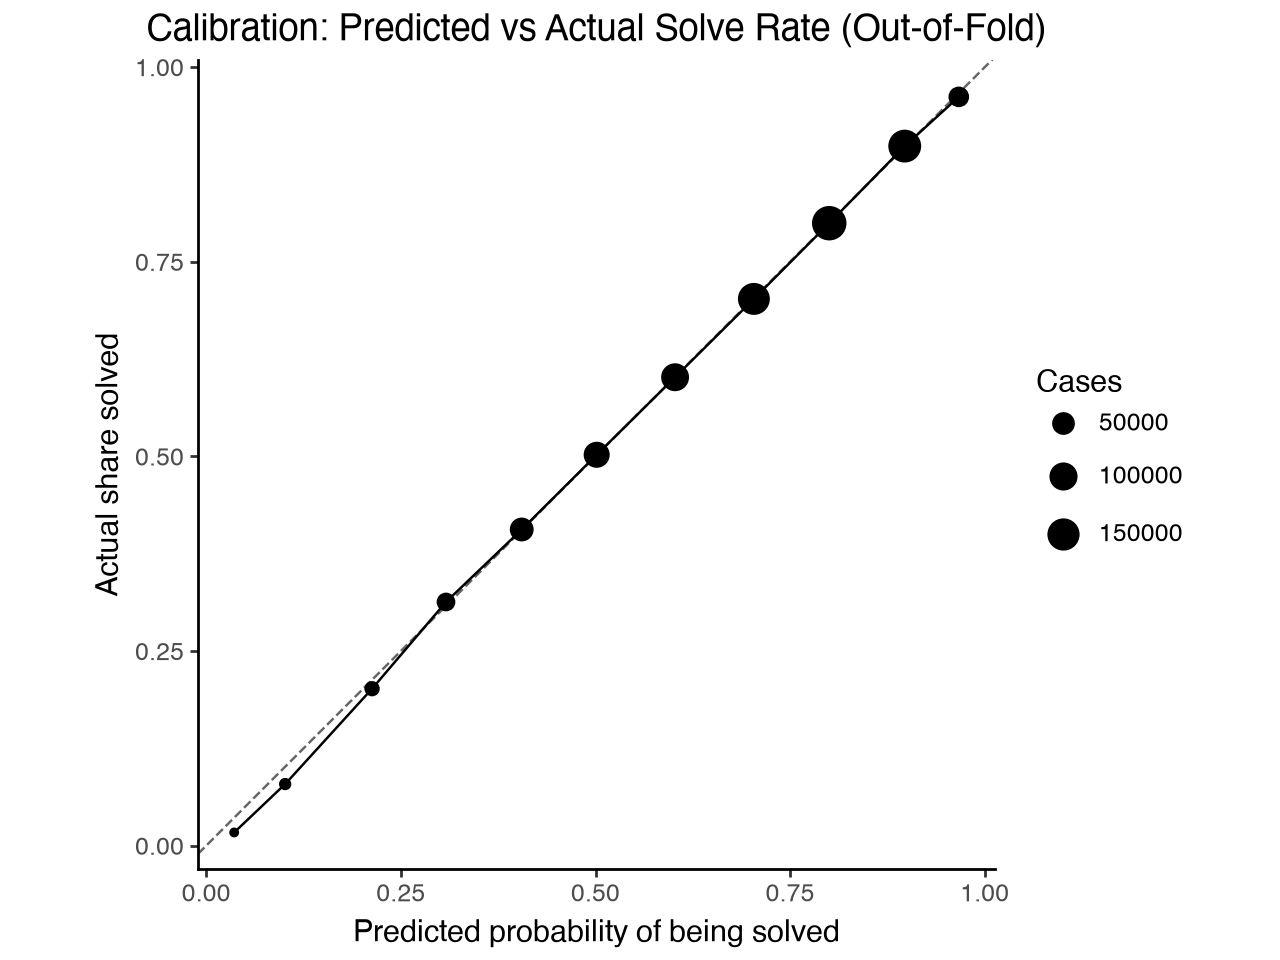

In [43]:
calib_table = df.groupby("bin", as_index=False).agg(
    predicted=("p_solved", "mean"),
    actual=("solved", "mean"),
    n=("solved", "size"),
)

(ggplot(calib_table, aes(x="predicted", y="actual"))
 + geom_point(aes(size="n"))
 + geom_line()
 + geom_abline(intercept=0, slope=1, linetype="dashed", alpha=0.6)
 + coord_equal()
 + theme_classic()
 + labs(title="Calibration: Predicted vs Actual Solve Rate (Out-of-Fold)",
        x="Predicted probability of being solved", y="Actual share solved", size="Cases"))

In [44]:
def calib_by(col):
    t = df.groupby(col, as_index=False).agg(
        n=("solved", "size"),
        predicted=("p_solved", "mean"),
        actual=("solved", "mean"),
    )
    t["gap_pts"] = (t["actual"] - t["predicted"]) * 100
    return t.sort_values("gap_pts")

display(calib_by("Decade"))
display(calib_by("Weapon_grp"))

,Decade,n,predicted,actual,gap_pts
2,1990,201301,0.681740,0.681308,-0.043148
1,1980,195912,0.726547,0.726117,-0.042982
0,1970,76717,0.759673,0.759323,-0.035014
4,2010,158319,0.681727,0.681466,-0.026159
3,2000,160895,0.687457,0.687287,-0.017033


,Weapon_grp,n,predicted,actual,gap_pts
2,Explosives,603,0.709319,0.698176,-1.114369
12,Pushed or thrown out window,248,0.874312,0.866935,-0.737615
3,Fire,7471,0.670809,0.664436,-0.637326
1,Drowning,1255,0.793991,0.789641,-0.434917
11,Poison - does not include gas,538,0.835322,0.832714,-0.260850
15,Strangulation,14706,0.610863,0.609751,-0.111215
8,Other gun,3054,0.584816,0.583824,-0.099119
4,"Firearm, type not stated",68129,0.523645,0.522788,-0.085701
9,Other or type unknown,38978,0.554452,0.553825,-0.062701
0,"Blunt object - hammer, club, etc",35553,0.694515,0.693922,-0.059351


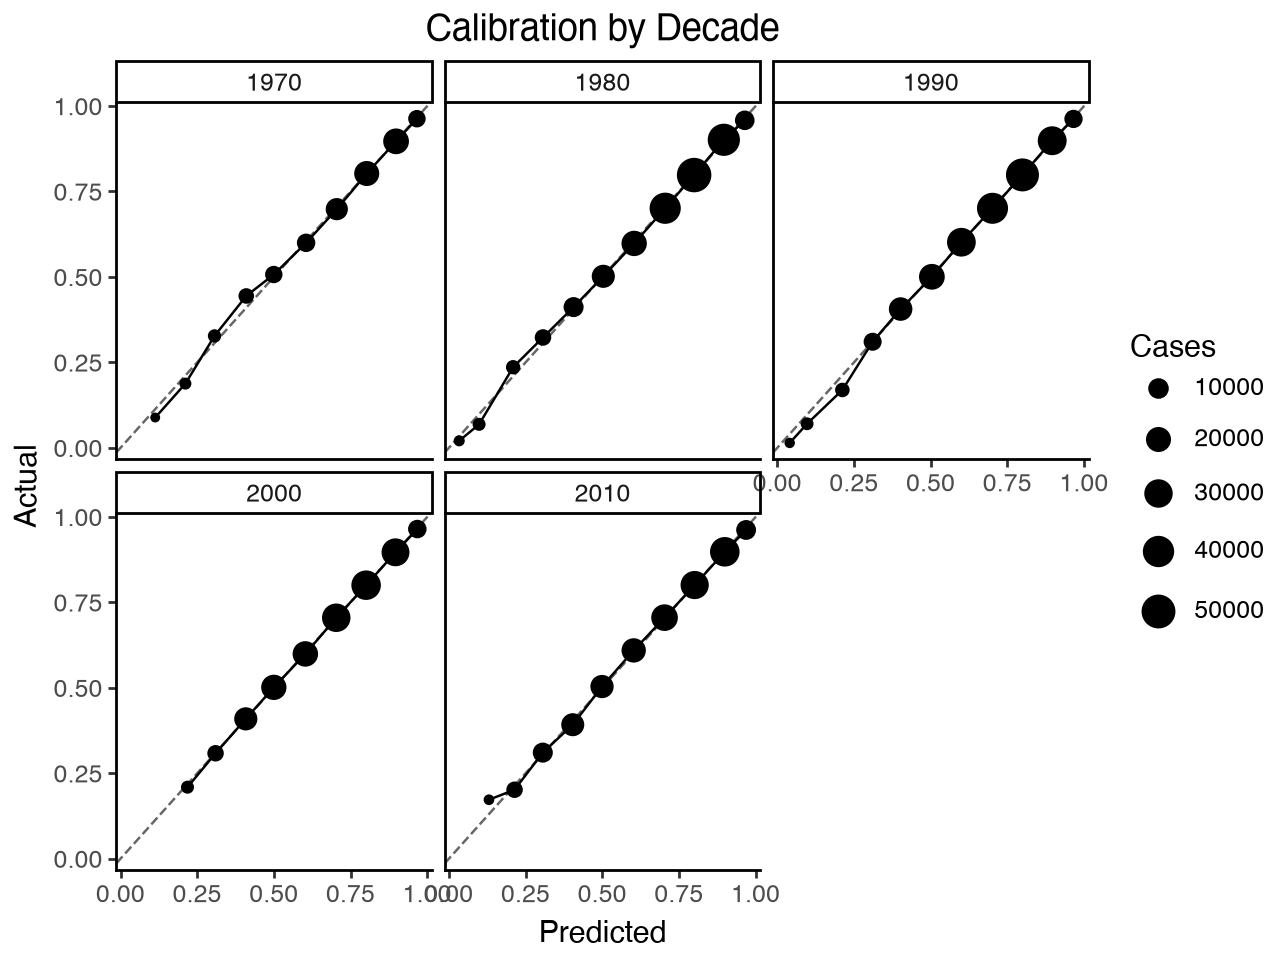

In [45]:
calib_dec = df.groupby(["Decade", "bin"], as_index=False).agg(
    predicted=("p_solved", "mean"),
    actual=("solved", "mean"),
    n=("solved", "size"),
)

(ggplot(calib_dec[calib_dec["n"] >= 100], aes(x="predicted", y="actual"))
 + geom_point(aes(size="n"))
 + geom_line()
 + geom_abline(intercept=0, slope=1, linetype="dashed", alpha=0.6)
 + facet_wrap("~Decade")
 + theme_classic()
 + labs(title="Calibration by Decade", x="Predicted", y="Actual", size="Cases"))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/plotnine/geoms/geom_path.py:112: PlotnineWarning: geom_path: Each group consist of only one observation. Do you need to adjust the group aesthetic?


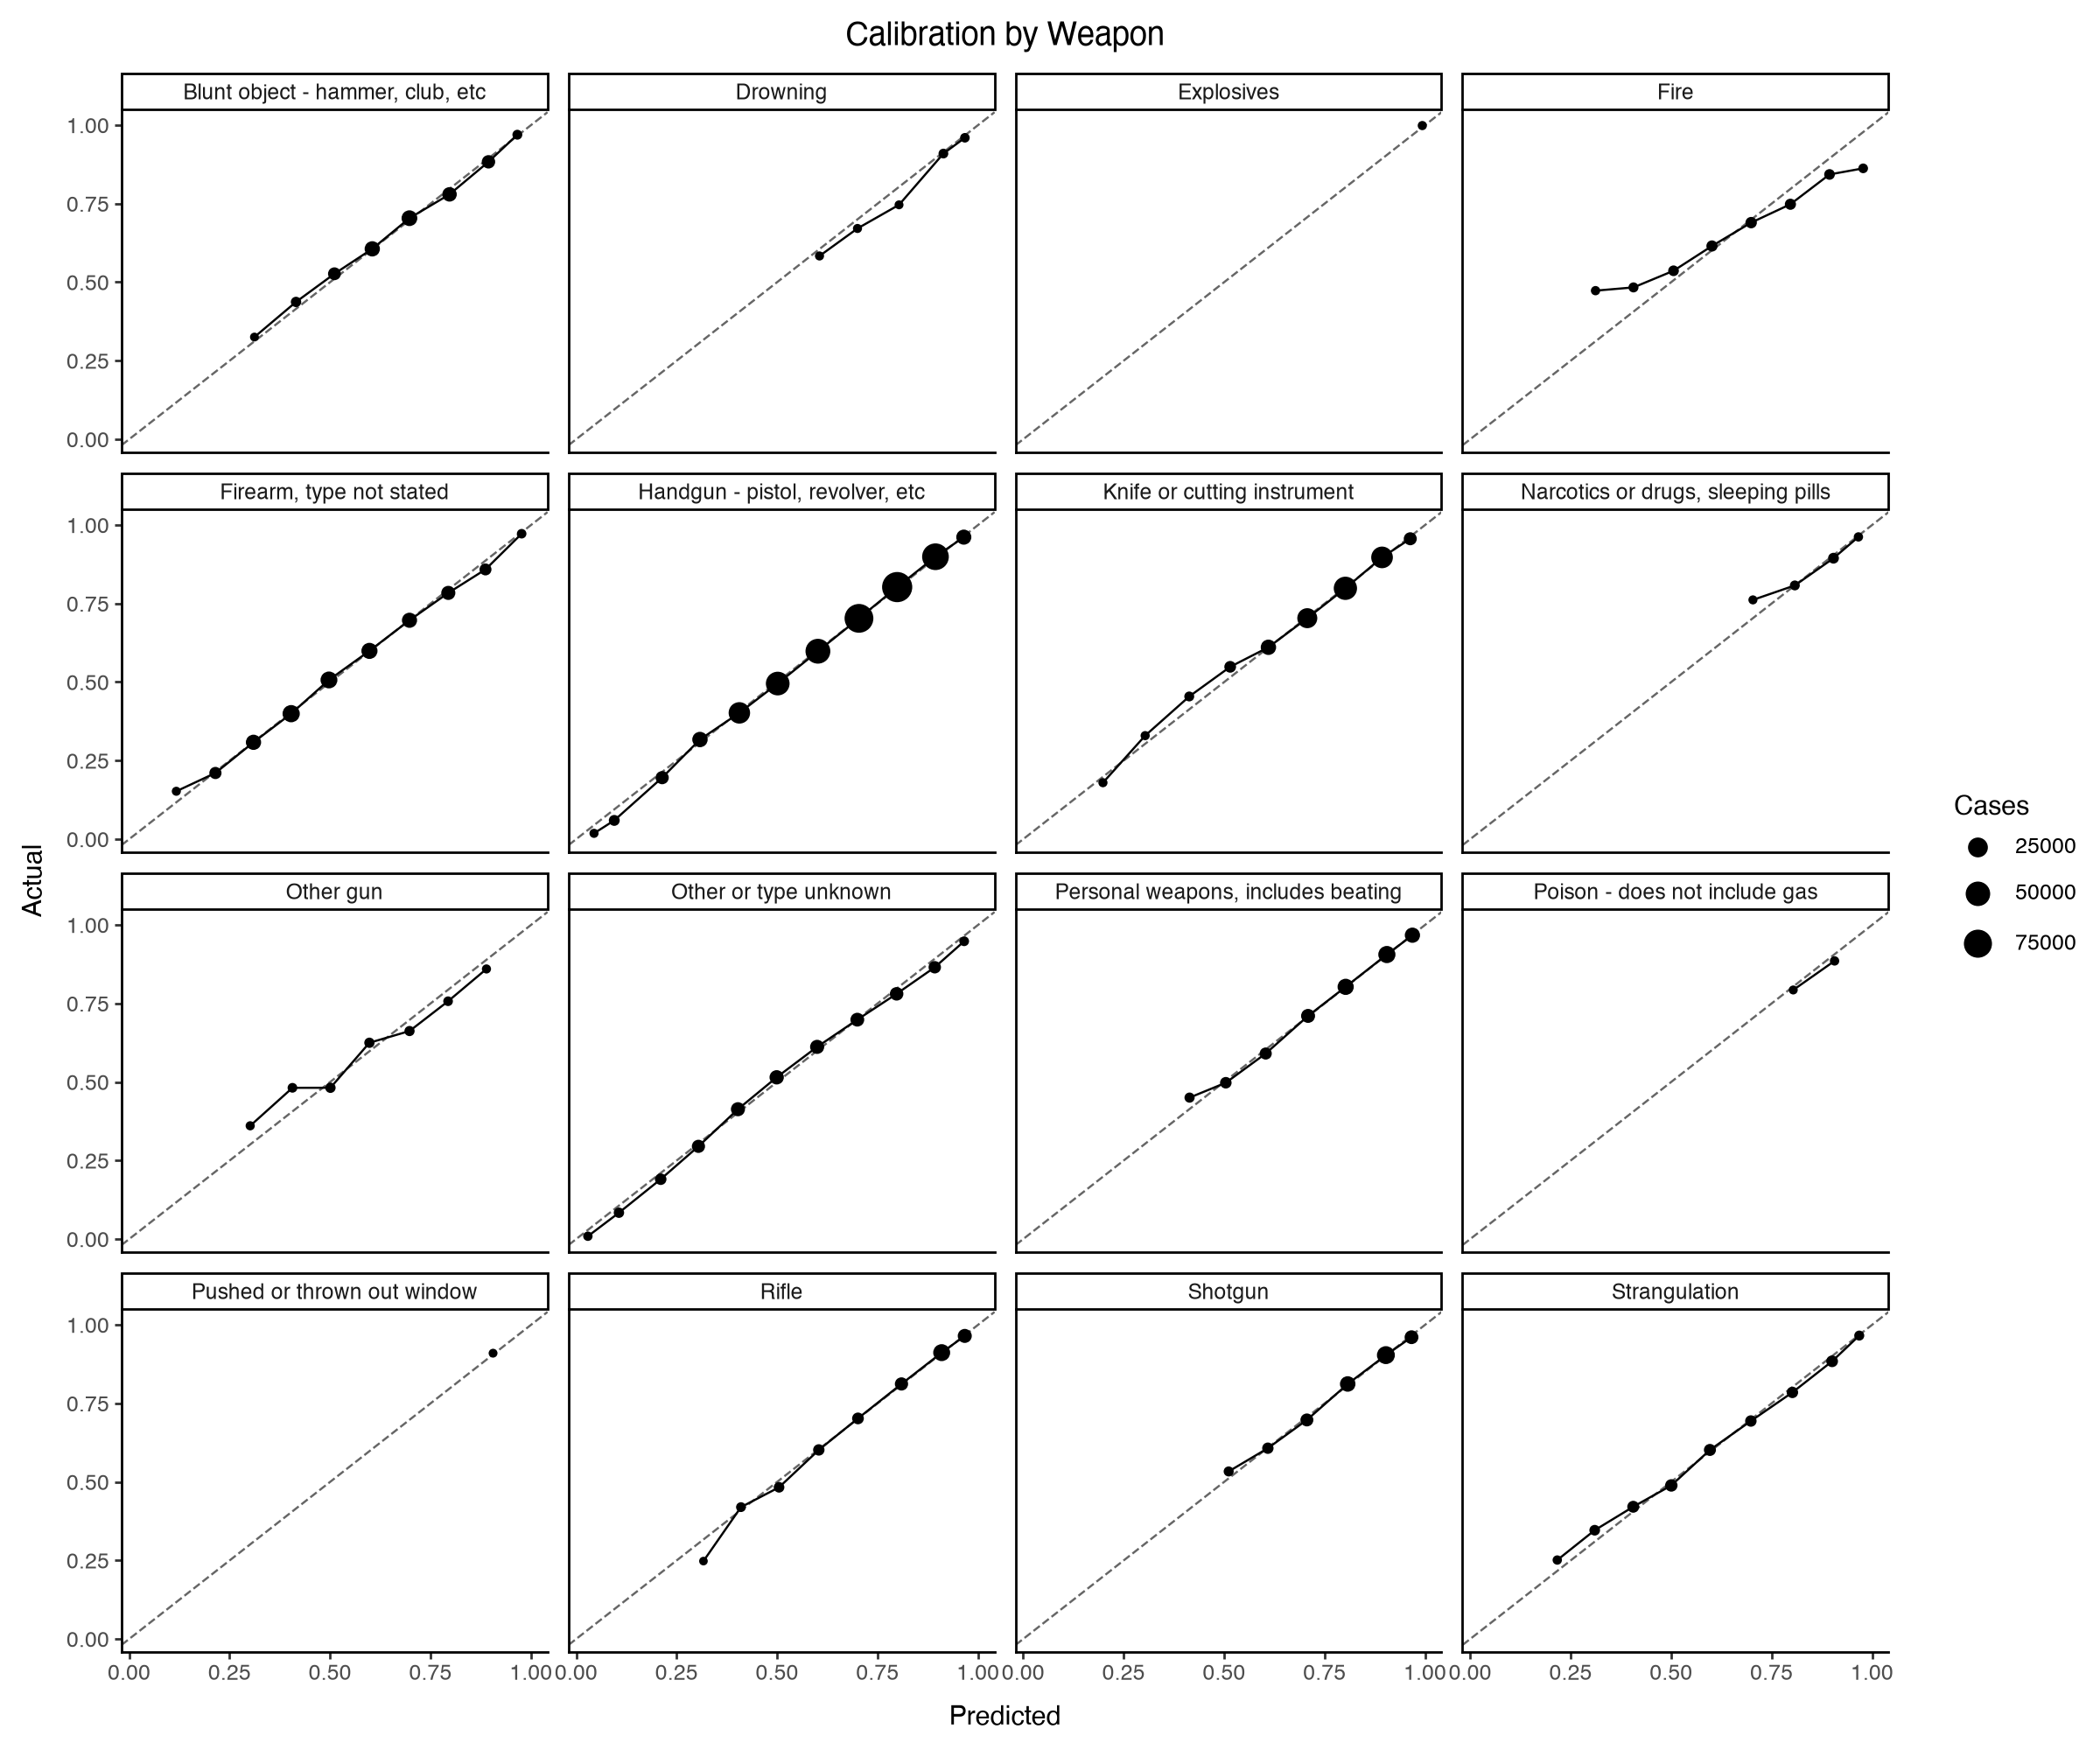

In [46]:
calib_wpn = df.groupby(["Weapon_grp", "bin"], as_index=False).agg(
    predicted=("p_solved", "mean"),
    actual=("solved", "mean"),
    n=("solved", "size"),
)

(ggplot(calib_wpn[calib_wpn["n"] >= 100], aes(x="predicted", y="actual"))
 + geom_point(aes(size="n"))
 + geom_line()
 + geom_abline(intercept=0, slope=1, linetype="dashed", alpha=0.6)
 + facet_wrap("~Weapon_grp")
 + theme_classic()
 + theme(figure_size=(12, 10))
 + labs(title="Calibration by Weapon", x="Predicted", y="Actual", size="Cases"))

Overall, the points sit on the line, so the probabilities hold up. By decade, the biggest gap is the 1990s at −0.04 points. By weapon, the biggest gap is explosives at −1.1 points, and the common weapons are all within 0.2 points. None of these gaps are big enough to make a group look unusual on their own.

## Comparing Models
To check that XGBoost was worth it, I compared it to logistic regression and a single decision tree.

In [47]:
scaler = StandardScaler().fit(X_train_trans)
X_train_sc = scaler.transform(X_train_trans)
X_test_sc = scaler.transform(X_test_trans)

logit = LogisticRegression(max_iter=1000, random_state=123).fit(X_train_sc, y_train)
logit_pred = logit.predict_proba(X_test_sc)[:, 1]

logit_auc = roc_auc_score(y_test, logit_pred)
logit_acc = accuracy_score(y_test, (logit_pred >= 0.5).astype(int))
print(logit_auc, logit_acc)

0.6952687364287012 0.7124692681081762


AUC 0.695 and accuracy 0.712, barely better than guessing.

I picked the tree depth with cross-validation.

In [48]:
for d in [5, 10, 15, 20]:
    tree = DecisionTreeClassifier(max_depth=d, min_samples_leaf=50, random_state=123)
    print(d, cross_val_score(tree, X_train_trans, y_train, cv=cv_folds, scoring="roc_auc").mean())

5 0.6418976791287718
10 0.6986156194857813
15 0.7124914458585626
20 0.7177874207573919


In [49]:
for d in [25, 30, 40]:
    tree = DecisionTreeClassifier(max_depth=d, min_samples_leaf=50, random_state=123)
    print(d, cross_val_score(tree, X_train_trans, y_train, cv=cv_folds, scoring="roc_auc").mean())

25 0.7198656873187488
30 0.7197480360339596
40 0.7197119172583617


AUC levels off around depth 25 (0.720), so I used 25.

In [50]:
tree_final = DecisionTreeClassifier(max_depth=25, min_samples_leaf=50, random_state=123).fit(X_train_trans, y_train)
tree_pred = tree_final.predict_proba(X_test_trans)[:, 1]
tree_auc = roc_auc_score(y_test, tree_pred)
tree_acc = accuracy_score(y_test, (tree_pred >= 0.5).astype(int))

xgb_auc = roc_auc_score(y_test, test_pred_tuned)
xgb_acc = accuracy_score(y_test, (test_pred_tuned >= 0.5).astype(int))

compare_models = pd.DataFrame({
    "Model": ["Always guess 'solved'", "Logistic regression", "Decision tree (depth 25)", "XGBoost (tuned)"],
    "Test AUC": [0.5, logit_auc, tree_auc, xgb_auc],
    "Test accuracy": [accuracy_score(y_test, np.ones(len(y_test), dtype=int)), logit_acc, tree_acc, xgb_acc],
}).round(3)
compare_models.to_csv("../data/model_comparison.csv", index=False)
compare_models

,Model,Test AUC,Test accuracy
0,Always guess 'solved',0.500,0.701
1,Logistic regression,0.695,0.712
2,Decision tree (depth 25),0.723,0.729
3,XGBoost (tuned),0.748,0.740


XGBoost beats both. The biggest jump is from logistic regression to a single tree, so the factors behind solving a murder interact in ways a straight-line model misses.